In [1]:
# Identificación de Z1 y Z2, montando la señal MC Higgs, MC ZZ y los datos Run2012B y RUn 2012C, para el canal 4l
# ademas de aplixar delta R, Parámetro impacto dxy<0.5, dz<1.0 y una luminosidad de 11.46 fb inversos en archvios parquet de las columans con muones >= 4


In [2]:
import awkward as ak
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import mplhep as hep

In [3]:
df_4mu = pd.read_parquet("df_data_real_muones_BC.parquet")


# Verificamos que todo cargó bien imprimiendo los totales

print("Número de eventos con 4 muones listos para procesar (Datos Reales):", len(df_4mu))

Número de eventos con 4 muones listos para procesar (Datos Reales): 8343295


In [4]:
df_4mu_higgs = pd.read_parquet("df_higgs_4mu.parquet")
df_4mu_zz = pd.read_parquet("df_zz_4mu.parquet")

print("Número de eventos con 4 muones (Higgs MC):", len(df_4mu_higgs))
print("Número de eventos con 4 muones (ZZ MC):", len(df_4mu_zz))

Número de eventos con 4 muones (Higgs MC): 30534
Número de eventos con 4 muones (ZZ MC): 425182


In [5]:
# Ver las columnas de tus DataFrames de muones
print("Columnas en df_4mu:", df_4mu.columns.tolist())
print("Columnas en df_4mu_higgs:", df_4mu_higgs.columns.tolist())
print("Columnas en df_4mu_zz:", df_4mu_zz.columns.tolist())

Columnas en df_4mu: ['run', 'luminosityBlock', 'event', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_charge', 'Muon_pfRelIso04_all', 'Muon_dxy', 'Muon_dz', 'Muon_dxyErr', 'Muon_dzErr', 'pt1', 'eta1', 'phi1', 'charge1', 'iso1', 'dxy1', 'dz1', 'dzErr1', 'dxyErr1', 'pt2', 'eta2', 'phi2', 'charge2', 'iso2', 'dxy2', 'dz2', 'dxyErr2', 'dzErr2', 'pt3', 'eta3', 'phi3', 'charge3', 'iso3', 'dxy3', 'dz3', 'dxyErr3', 'dzErr3', 'pt4', 'eta4', 'phi4', 'charge4', 'iso4', 'dxy4', 'dz4', 'dxyErr4', 'dzErr4']
Columnas en df_4mu_higgs: ['run', 'luminosityBlock', 'event', 'Muon_pt', 'Muon_eta', 'Muon_phi', 'Muon_charge', 'Muon_pfRelIso04_all', 'Muon_dxy', 'Muon_dz', 'Muon_dxyErr', 'Muon_dzErr', 'pt1', 'eta1', 'phi1', 'charge1', 'iso1', 'dxy1', 'dz1', 'dzErr1', 'dxyErr1', 'pt2', 'eta2', 'phi2', 'charge2', 'iso2', 'dxy2', 'dz2', 'dxyErr2', 'dzErr2', 'pt3', 'eta3', 'phi3', 'charge3', 'iso3', 'dxy3', 'dz3', 'dxyErr3', 'dzErr3', 'pt4', 'eta4', 'phi4', 'charge4', 'iso4', 'dxy4', 'dz4', 'dxyErr4', 'dzErr4']
Columnas

In [6]:
# Quitamos valores negativos como los valores centinela ( -999) de las columnas de iso1, iso2, iso3, iso4

def solo_positivos(df): 
    mask_positivo = (df["iso1"] >= 0) & (df["iso2"] >= 0) & (df["iso3"] >= 0) & (df["iso4"] >= 0)
    return df[mask_positivo].copy()

# Aplicamos y guardamos el filtro de forma independiente para cada DataFrame
df_4mu  = solo_positivos(df_4mu)
df_4mu_higgs = solo_positivos(df_4mu_higgs)
df_4mu_zz    = solo_positivos(df_4mu_zz)

# Verificación final de los conteos limpios
print("Datos reales listos (sin -999):", len(df_4mu))
print("Higgs MC listo (sin -999):     ", len(df_4mu_higgs))
print("ZZ MC listo (sin -999):        ", len(df_4mu_zz))

Datos reales listos (sin -999): 291208
Higgs MC listo (sin -999):      22473
ZZ MC listo (sin -999):         330896


In [7]:
# Comprobar si son el mismo objeto en memoria
print("¿Son el mismo DataFrame en memoria?", df_4mu is df_4mu_higgs)
# Verificamos los valores mínimos de aislamiento en los datos limpios
print("Mínimos de aislamiento (Datos):\n", df_4mu[["iso1", "iso2", "iso3", "iso4"]].min())

¿Son el mismo DataFrame en memoria? False
Mínimos de aislamiento (Datos):
 iso1    0.0
iso2    0.0
iso3    0.0
iso4    0.0
dtype: float64


In [7]:
# ¿Cuántos -999 hay en CADA columna de aislamiento?
for i in range(1, 5):
    n_centinela = (df_4mu[f"iso{i}"] == -999).sum()
    print(f"iso{i}: {n_centinela} valores -999 de {len(df_4mu)} ({100*n_centinela/len(df_4mu):.1f}%)")

iso1: 0 valores -999 de 291208 (0.0%)
iso2: 0 valores -999 de 291208 (0.0%)
iso3: 0 valores -999 de 291208 (0.0%)
iso4: 0 valores -999 de 291208 (0.0%)


In [22]:
# Tabla de Flujo de Cortes para 4 muones 1

# # Función auxiliar para calcular Delta R respetando la periodicidad de phi [-pi, pi]

def calc_dr(eta1, phi1, eta2, phi2):
  deta = eta1 - eta2
  dphi = (phi1 - phi2 + np.pi) % (2 * np.pi) - np.pi
  return np.sqrt(deta**2 + dphi**2)

# Datos Reales (4 muones)

for i in range(1, 5):
  ip3d = np.sqrt(df_4mu[f"dxy{i}"] ** 2 + df_4mu[f"dz{i}"] ** 2)
  sig = np.sqrt(df_4mu[f"dxyErr{i}"] ** 2 + df_4mu[f"dzErr{i}"] ** 2)
  df_4mu[f"sip3d{i}"] = ip3d / sig

dr_12 = calc_dr(
    df_4mu["eta1"], df_4mu["phi1"], df_4mu["eta2"], df_4mu["phi2"]
)
dr_13 = calc_dr(
    df_4mu["eta1"], df_4mu["phi1"], df_4mu["eta3"], df_4mu["phi3"]
)
dr_14 = calc_dr(
    df_4mu["eta1"], df_4mu["phi1"], df_4mu["eta4"], df_4mu["phi4"]
)
dr_23 = calc_dr(
    df_4mu["eta2"], df_4mu["phi2"], df_4mu["eta3"], df_4mu["phi3"]
)
dr_24 = calc_dr(
    df_4mu["eta2"], df_4mu["phi2"], df_4mu["eta4"], df_4mu["phi4"]
)
dr_34 = calc_dr(
    df_4mu["eta3"], df_4mu["phi3"], df_4mu["eta4"], df_4mu["phi4"]
)

mask_pt = ((df_4mu["pt1"] > 5)& (df_4mu["pt2"] > 5) & (df_4mu["pt3"] > 5) & (df_4mu["pt4"] > 5))
mask_eta = (df_4mu["eta1"].abs() < 2.4) & (df_4mu["eta2"].abs() < 2.4) & (df_4mu["eta3"].abs() < 2.4) & (df_4mu["eta4"].abs() < 2.4) 
mask_iso = ((df_4mu["iso1"] < 0.40) & (df_4mu["iso2"] < 0.40) & (df_4mu["iso3"] < 0.40) & (df_4mu["iso4"] < 0.40))
mask_sip = ((df_4mu["sip3d1"] < 4) & (df_4mu["sip3d2"] < 4) & (df_4mu["sip3d3"] < 4) & (df_4mu["sip3d4"] < 4) )
mask_dxy = ((df_4mu["dxy1"].abs() < 0.5) & (df_4mu["dxy2"].abs() < 0.5) & (df_4mu["dxy3"].abs() < 0.5) & (df_4mu["dxy4"].abs() < 0.5))
mask_dz = ((df_4mu["dz1"].abs() < 1.0) & (df_4mu["dz2"].abs() < 1.0) & (df_4mu["dz3"].abs() < 1.0) & (df_4mu["dz4"].abs() < 1.0))
mask_dr = ((dr_12 > 0.02) & (dr_13 > 0.02) & (dr_14 > 0.02) & (dr_23 > 0.02) & (dr_24 > 0.02) & (dr_34 > 0.02))

df_final = df_4mu[mask_pt & mask_eta & mask_iso & mask_sip & mask_dxy & mask_dz & mask_dr].copy()

n_total = len(df_4mu)
n_pt = len(df_4mu[mask_pt])
n_eta = len(df_4mu[mask_pt & mask_eta])
n_iso = len(df_4mu[mask_pt & mask_eta & mask_iso])
n_sip = len(df_4mu[mask_pt & mask_eta & mask_iso & mask_sip])
n_dxy_dz = len(df_4mu[mask_pt & mask_eta & mask_iso & mask_sip & mask_dxy & mask_dz])
n_dr = len(df_4mu[mask_pt & mask_eta & mask_iso & mask_sip & mask_dxy & mask_dz & mask_dr])

data_flujo = {
    "Corte aplicado": [
        "Sin filtros (4 muones)",
        "pT Líderes (>5 GeV)",
        "Aceptancia Detector (|eta| < 2.4)",
        "Aislamiento iso < 0.40",
        "Parámetro impacto sip3d < 4",
        "Vértice dxy < 0.5, dz < 1.0",
        "Separación Delta R > 0.02 (Final)",
    ],
    "Eventos Restantes": [n_total, n_pt, n_eta, n_iso, n_sip, n_dxy_dz, n_dr],
    "Aceptancia (%)": [
        100.0,
        (n_pt / n_total) * 100,
        (n_eta / n_total) * 100,
        (n_iso / n_total) * 100,
        (n_sip / n_total) * 100,
        (n_dxy_dz / n_total) * 100,
        (n_dr / n_total) * 100,
    ],
}
tabla_flujo = pd.DataFrame(data_flujo)
print("\nTabla de Flujo de Cortes (Canal H -> ZZ* -> 4mu - Datos Reales)")
print(tabla_flujo)


# HIGGS MC (df_4mu_higgs)
for i in range(1, 5):
  ip3d_h = np.sqrt(df_4mu_higgs[f"dxy{i}"] ** 2 + df_4mu_higgs[f"dz{i}"] ** 2)
  sig_h = np.sqrt(
      df_4mu_higgs[f"dxyErr{i}"] ** 2 + df_4mu_higgs[f"dzErr{i}"] ** 2
  )
  df_4mu_higgs[f"sip3d{i}"] = ip3d_h / sig_h

dr_12_h = calc_dr(df_4mu_higgs["eta1"], df_4mu_higgs["phi1"], df_4mu_higgs["eta2"], df_4mu_higgs["phi2"],)
dr_13_h = calc_dr( df_4mu_higgs["eta1"],df_4mu_higgs["phi1"],df_4mu_higgs["eta3"],df_4mu_higgs["phi3"],)
dr_14_h = calc_dr(df_4mu_higgs["eta1"],df_4mu_higgs["phi1"],df_4mu_higgs["eta4"],df_4mu_higgs["phi4"],)
dr_23_h = calc_dr(df_4mu_higgs["eta2"],df_4mu_higgs["phi2"],df_4mu_higgs["eta3"],df_4mu_higgs["phi3"],)
dr_24_h = calc_dr(df_4mu_higgs["eta2"], df_4mu_higgs["phi2"], df_4mu_higgs["eta4"], df_4mu_higgs["phi4"],)
dr_34_h = calc_dr(df_4mu_higgs["eta3"], df_4mu_higgs["phi3"], df_4mu_higgs["eta4"], df_4mu_higgs["phi4"],)

mask_pt_h = ((df_4mu_higgs["pt1"] > 5)& (df_4mu_higgs["pt2"] > 5)& (df_4mu_higgs["pt3"] > 5)& (df_4mu_higgs["pt4"] > 5))
mask_eta_h = mask_pt_h & ((df_4mu_higgs["eta1"].abs() < 2.4) & (df_4mu_higgs["eta2"].abs() < 2.4) & (df_4mu_higgs["eta3"].abs() < 2.4)& (df_4mu_higgs["eta4"].abs() < 2.4))
mask_iso_h = mask_eta_h & ((df_4mu_higgs["iso1"] < 0.40) & (df_4mu_higgs["iso2"] < 0.40) & (df_4mu_higgs["iso3"] < 0.40) & (df_4mu_higgs["iso4"] < 0.40))
mask_sip_h = mask_iso_h & ((df_4mu_higgs["sip3d1"] < 4) & (df_4mu_higgs["sip3d2"] < 4)& (df_4mu_higgs["sip3d3"] < 4) & (df_4mu_higgs["sip3d4"] < 4))
mask_dxy_h = mask_sip_h & ((df_4mu_higgs["dxy1"].abs() < 0.5)& (df_4mu_higgs["dxy2"].abs() < 0.5)& (df_4mu_higgs["dxy3"].abs() < 0.5)& (df_4mu_higgs["dxy4"].abs() < 0.5))
mask_dz_h = mask_dxy_h & ((df_4mu_higgs["dz1"].abs() < 1.0) & (df_4mu_higgs["dz2"].abs() < 1.0)& (df_4mu_higgs["dz3"].abs() < 1.0)& (df_4mu_higgs["dz4"].abs() < 1.0))
mask_dr_h = mask_dz_h & ((dr_12_h > 0.02) & (dr_13_h > 0.02) & (dr_14_h > 0.02) & (dr_23_h > 0.02) & (dr_24_h > 0.02) & (dr_34_h > 0.02))

df_final_higgs = df_4mu_higgs[mask_pt_h & mask_eta_h & mask_iso_h & mask_sip_h & mask_dxy_h & mask_dz_h & mask_dr_h].copy()

n_total_h = len(df_4mu_higgs)
n_pt_h = len(df_4mu_higgs[mask_pt_h])
n_eta_h = len(df_4mu_higgs[mask_eta_h])
n_iso_h = len(df_4mu_higgs[mask_iso_h])
n_sip_h = len(df_4mu_higgs[mask_sip_h])
n_dxy_dz_h = len(df_4mu_higgs[mask_dz_h])
n_dr_h = len(df_4mu_higgs[mask_dr_h])

tabla_flujo_h = pd.DataFrame({
    "Corte aplicado": [
        "Sin filtros (Higgs MC)",
        "pT Líderes (>5 GeV)",
        "Aceptancia Detector (|eta| < 2.4)",
        "Aislamiento iso < 0.40",
        "Parámetro impacto sip3d < 4",
        "Vértice dxy < 0.5, dz < 1.0",
        "Separación Delta R > 0.02 (Final)",
    ],
    "Eventos Restantes": [
        n_total_h,
        n_pt_h,
        n_eta_h,
        n_iso_h,
        n_sip_h,
        n_dxy_dz_h,
        n_dr_h,
    ],
    "Aceptancia (%)": [
        100.0,
        (n_pt_h / n_total_h) * 100 if n_total_h > 0 else 0,
        (n_eta_h / n_total_h) * 100 if n_total_h > 0 else 0,
        (n_iso_h / n_total_h) * 100 if n_total_h > 0 else 0,
        (n_sip_h / n_total_h) * 100 if n_total_h > 0 else 0,
        (n_dxy_dz_h / n_total_h) * 100 if n_total_h > 0 else 0,
        (n_dr_h / n_total_h) * 100 if n_total_h > 0 else 0,
    ],
})
print("\nTabla de Flujo de Cortes (Canal H -> ZZ* -> 4mu - Higgs MC)")
print(tabla_flujo_h.to_string(index=False))


# Fondo ZZ MC (df_4mu_zz)

for i in range(1, 5):
  ip3d_zz = np.sqrt(df_4mu_zz[f"dxy{i}"] ** 2 + df_4mu_zz[f"dz{i}"] ** 2)
  sig_zz = np.sqrt(
      df_4mu_zz[f"dxyErr{i}"] ** 2 + df_4mu_zz[f"dzErr{i}"] ** 2
  )
  df_4mu_zz[f"sip3d{i}"] = ip3d_zz / sig_zz

dr_12_zz = calc_dr(df_4mu_zz["eta1"],df_4mu_zz["phi1"],df_4mu_zz["eta2"],df_4mu_zz["phi2"],)
dr_13_zz = calc_dr(df_4mu_zz["eta1"],df_4mu_zz["phi1"],df_4mu_zz["eta3"],df_4mu_zz["phi3"],)
dr_14_zz = calc_dr(df_4mu_zz["eta1"],df_4mu_zz["phi1"],df_4mu_zz["eta4"],df_4mu_zz["phi4"],)
dr_23_zz = calc_dr(df_4mu_zz["eta2"],df_4mu_zz["phi2"],df_4mu_zz["eta3"],df_4mu_zz["phi3"],)
dr_24_zz = calc_dr(df_4mu_zz["eta2"],df_4mu_zz["phi2"],df_4mu_zz["eta4"],df_4mu_zz["phi4"],)
dr_34_zz = calc_dr(df_4mu_zz["eta3"],df_4mu_zz["phi3"],df_4mu_zz["eta4"],df_4mu_zz["phi4"],)

mask_pt_zz = ((df_4mu_zz["pt1"] > 5)& (df_4mu_zz["pt2"] > 5)& (df_4mu_zz["pt3"] > 5) & (df_4mu_zz["pt4"] > 5))
mask_eta_zz = ((df_4mu_zz["eta1"].abs() < 2.4)& (df_4mu_zz["eta2"].abs() < 2.4)& (df_4mu_zz["eta3"].abs() < 2.4)& (df_4mu_zz["eta4"].abs() < 2.4))
mask_iso_zz = ((df_4mu_zz["iso1"] < 0.40)& (df_4mu_zz["iso2"] < 0.40)& (df_4mu_zz["iso3"] < 0.40)& (df_4mu_zz["iso4"] < 0.40))
mask_sip_zz = ((df_4mu_zz["sip3d1"] < 4)& (df_4mu_zz["sip3d2"] < 4)& (df_4mu_zz["sip3d3"] < 4) & (df_4mu_zz["sip3d4"] < 4))
mask_dxy_zz = ((df_4mu_zz["dxy1"].abs() < 0.5)& (df_4mu_zz["dxy2"].abs() < 0.5)& (df_4mu_zz["dxy3"].abs() < 0.5)& (df_4mu_zz["dxy4"].abs() < 0.5))
mask_dz_zz = ((df_4mu_zz["dz1"].abs() < 1.0) & (df_4mu_zz["dz2"].abs() < 1.0)& (df_4mu_zz["dz3"].abs() < 1.0)& (df_4mu_zz["dz4"].abs() < 1.0))
mask_dr_zz = ((dr_12_zz > 0.02)& (dr_13_zz > 0.02)& (dr_14_zz > 0.02)& (dr_23_zz > 0.02)& (dr_24_zz > 0.02) & (dr_34_zz > 0.02))

df_final_zz = df_4mu_zz[mask_pt_zz & mask_eta_zz & mask_iso_zz & mask_sip_zz & mask_dxy_zz & mask_dz_zz & mask_dr_zz].copy()

n_total_zz = len(df_4mu_zz)
n_pt_zz = len(df_4mu_zz[mask_pt_zz])
n_eta_zz = len(df_4mu_zz[mask_pt_zz & mask_eta_zz])
n_iso_zz = len(df_4mu_zz[mask_pt_zz & mask_eta_zz & mask_iso_zz])
n_sip_zz = len(df_4mu_zz[mask_pt_zz & mask_eta_zz & mask_iso_zz & mask_sip_zz])
n_dxy_dz_zz = len(df_4mu_zz[mask_pt_zz & mask_eta_zz & mask_iso_zz & mask_sip_zz & mask_dxy_zz & mask_dz_zz])
n_dr_zz = len(df_4mu_zz[mask_pt_zz & mask_eta_zz & mask_iso_zz & mask_sip_zz & mask_dxy_zz & mask_dz_zz & mask_dr_zz])
data_flujo_zz = {
    "Corte aplicado": [
        "Sin filtros (Fondo ZZ MC)",
        "pT Líderes (>5 GeV)",
        "Aceptancia Detector (|eta| < 2.4)",
        "Aislamiento iso < 0.40",
        "Parámetro impacto sip3d < 4",
        "Vértice dxy < 0.5, dz < 1.0",
        "Separación Delta R > 0.02 (Final)",
    ],
    "Eventos Restantes": [
        n_total_zz,
        n_pt_zz,
        n_eta_zz,
        n_iso_zz,
        n_sip_zz,
        n_dxy_dz_zz,
        n_dr_zz,
    ],
    "Aceptancia (%)": [
        100.0,
        (n_pt_zz / n_total_zz) * 100 if n_total_zz > 0 else 0,
        (n_eta_zz / n_total_zz) * 100 if n_total_zz > 0 else 0,
        (n_iso_zz / n_total_zz) * 100 if n_total_zz > 0 else 0,
        (n_sip_zz / n_total_zz) * 100 if n_total_zz > 0 else 0,
        (n_dxy_dz_zz / n_total_zz) * 100 if n_total_zz > 0 else 0,
        (n_dr_zz / n_total_zz) * 100 if n_total_zz > 0 else 0,
    ],
}
tabla_flujo_zz = pd.DataFrame(data_flujo_zz)
print("\nTabla de Flujo de Cortes (Canal H -> ZZ* -> 4mu - Fondo ZZ MC)")
print(tabla_flujo_zz.to_string(index=False))





Tabla de Flujo de Cortes (Canal H -> ZZ* -> 4mu - Datos Reales)
                      Corte aplicado  Eventos Restantes  Aceptancia (%)
0             Sin filtros (4 muones)             291208      100.000000
1                pT Líderes (>5 GeV)              72655       24.949521
2  Aceptancia Detector (|eta| < 2.4)              72009       24.727686
3             Aislamiento iso < 0.40               1258        0.431994
4        Parámetro impacto sip3d < 4                540        0.185434
5        Vértice dxy < 0.5, dz < 1.0                305        0.104736
6  Separación Delta R > 0.02 (Final)                262        0.089970

Tabla de Flujo de Cortes (Canal H -> ZZ* -> 4mu - Higgs MC)
                   Corte aplicado  Eventos Restantes  Aceptancia (%)
           Sin filtros (Higgs MC)              22473      100.000000
              pT Líderes (>5 GeV)              19845       88.305967
Aceptancia Detector (|eta| < 2.4)              19582       87.135674
           Aislamiento

In [23]:
# Constantes físicas para muones

M_Muon = 0.105658375
Z_Mass_Nominal = 91.1876


# Función auxiliar para calcular Delta R (respetando periodicidad en phi)
def delta_r(eta1, phi1, eta2, phi2):
    d_eta = eta1 - eta2
    d_phi = np.arctan2(np.sin(phi1 - phi2), np.cos(phi1 - phi2))
    return np.sqrt(d_eta**2 + d_phi**2)

# Función para masa de un par de muones
def masa_par(df, i, j):
    px = df[f"pt{i}"] * np.cos(df[f"phi{i}"]) + df[f"pt{j}"] * np.cos(
        df[f"phi{j}"]
    )
    py = df[f"pt{i}"] * np.sin(df[f"phi{i}"]) + df[f"pt{j}"] * np.sin(
        df[f"phi{j}"]
    )
    pz = df[f"pt{i}"] * np.sinh(df[f"eta{i}"]) + df[f"pt{j}"] * np.sinh(
        df[f"eta{j}"]
    )
    E = np.sqrt(
        df[f"pt{i}"] ** 2 + df[f"pt{i}"] ** 2 * np.sinh(df[f"eta{i}"]) ** 2 + M_Muon**2
    ) + np.sqrt(
        df[f"pt{j}"] ** 2 + df[f"pt{j}"] ** 2 * np.sinh(df[f"eta{j}"]) ** 2 + M_Muon**2
    )
    return np.sqrt(np.maximum(0.0, E**2 - (px**2 + py**2 + pz**2)))


# Identificación directa de Z1 y Z2

def identificar_Z_onoff(df):

    pares = [((1, 2), (3, 4)), ((1, 3), (2, 4)), ((1, 4), (2, 3))]

    mejor_mZ1, mejor_mZ2, mejor_diff = (
        np.full(len(df), np.nan),
        np.full(len(df), np.nan),
        np.full(len(df), np.inf),
    )

    mejor_dr_valido = np.zeros(len(df), dtype=bool)

    mejor_idx_a = np.zeros(len(df), dtype=int)
    mejor_idx_b = np.zeros(len(df), dtype=int)
    mejor_idx_c = np.zeros(len(df), dtype=int)
    mejor_idx_d = np.zeros(len(df), dtype=int)

    for (a, b), (c, d) in pares:
        valido = (df[f"charge{a}"] + df[f"charge{b}"] == 0) & (
            df[f"charge{c}"] + df[f"charge{d}"] == 0
        )
        
        dr_ab = delta_r(df[f"eta{a}"], df[f"phi{a}"], df[f"eta{b}"], df[f"phi{b}"])
        dr_cd = delta_r(df[f"eta{c}"], df[f"phi{c}"], df[f"eta{d}"], df[f"phi{d}"])
        dr_par = (dr_ab > 0.02) & (dr_cd > 0.02)

        m_ab, m_cd = masa_par(df, a, b), masa_par(df, c, d)

        ab_es_z1 = np.abs(m_ab - Z_Mass_Nominal) < np.abs(m_cd - Z_Mass_Nominal)
        m1 = np.where(ab_es_z1, m_ab, m_cd)
        m2 = np.where(ab_es_z1, m_cd, m_ab)
        idx_a = np.where(ab_es_z1, a, c)
        idx_b = np.where(ab_es_z1, b, d)
        idx_c = np.where(ab_es_z1, c, a)
        idx_d = np.where(ab_es_z1, d, b)

        diff = np.abs(m1 - Z_Mass_Nominal)
        mask = valido & (diff < mejor_diff)
        
        mejor_mZ1, mejor_mZ2, mejor_diff = (
            np.where(mask, m1, mejor_mZ1),
            np.where(mask, m2, mejor_mZ2),
            np.where(mask, diff, mejor_diff),
        )
        
        mejor_dr_valido = np.where(mask, dr_par, mejor_dr_valido)

        mejor_idx_a = np.where(mask, idx_a, mejor_idx_a)
        mejor_idx_b = np.where(mask, idx_b, mejor_idx_b)
        mejor_idx_c = np.where(mask, idx_c, mejor_idx_c)
        mejor_idx_d = np.where(mask, idx_d, mejor_idx_d)

    valido_final = ~np.isnan(mejor_mZ1) & mejor_dr_valido

    df["mZ1"] = np.where(valido_final, mejor_mZ1, np.nan)
    df["mZ2"] = np.where(valido_final, mejor_mZ2, np.nan)

    df["Z1_idx_a"], df["Z1_idx_b"] = mejor_idx_a, mejor_idx_b
    df["Z2_idx_c"], df["Z2_idx_d"] = mejor_idx_c, mejor_idx_d
    return df


# Datos Reales

df_final_mu = identificar_Z_onoff(df_final)
print(df_final_mu[["mZ1", "mZ2"]].describe())

# Aplicar los cortes de masa del skim

df_final_mu = df_final_mu[
    (df_final_mu["mZ1"] > 40) & (df_final_mu["mZ1"] < 120) &
    (df_final_mu["mZ2"] > 12) & (df_final_mu["mZ2"] < 120)
].copy()

print("Eventos después del skim de masa (Datos):", len(df_final_mu))


# HIGGS MC

df_final_higgs_mu = identificar_Z_onoff(df_final_higgs)
print("\nHiggs MC:")
print(df_final_higgs_mu[["mZ1", "mZ2"]].describe())

df_final_higgs_mu = df_final_higgs_mu[
    (df_final_higgs_mu["mZ1"] > 40) & (df_final_higgs_mu["mZ1"] < 120) &
    (df_final_higgs_mu["mZ2"] > 12) & (df_final_higgs_mu["mZ2"] < 120)
].copy()
print("Eventos después del skim de masa (Higgs):", len(df_final_higgs_mu))


# ZZ MC

df_final_zz_mu = identificar_Z_onoff(df_final_zz)
print("\nZZ MC:")
print(df_final_zz_mu[["mZ1", "mZ2"]].describe())

df_final_zz_mu = df_final_zz_mu[
    (df_final_zz_mu["mZ1"] > 40) & (df_final_zz_mu["mZ1"] < 120) &
    (df_final_zz_mu["mZ2"] > 12) & (df_final_zz_mu["mZ2"] < 120)
].copy()
print("Eventos después del skim de masa (ZZ):", len(df_final_zz_mu))

              mZ1         mZ2
count  258.000000  258.000000
mean    63.662951   27.376600
std     27.075738   36.671833
min      3.105455    0.259336
25%     50.337925    1.760497
50%     66.039873   10.176030
75%     89.750443   32.431198
max    110.585561  181.520966
Eventos después del skim de masa (Datos): 98

Higgs MC:
                mZ1           mZ2
count  12052.000000  12052.000000
mean      82.591344     27.466732
std       11.682876     11.271860
min       18.528431      0.376194
25%       76.067838     20.235080
50%       87.850963     27.031857
75%       90.884058     33.003177
max      118.378443     62.263781
Eventos después del skim de masa (Higgs): 10999

ZZ MC:
                 mZ1            mZ2
count  146215.000000  146215.000000
mean       78.185495      51.655124
std        18.069167      47.332297
min         5.392818       0.732601
25%        63.445556      11.184006
50%        89.115101      32.811147
75%        91.393499      89.415727
max       295.833745    

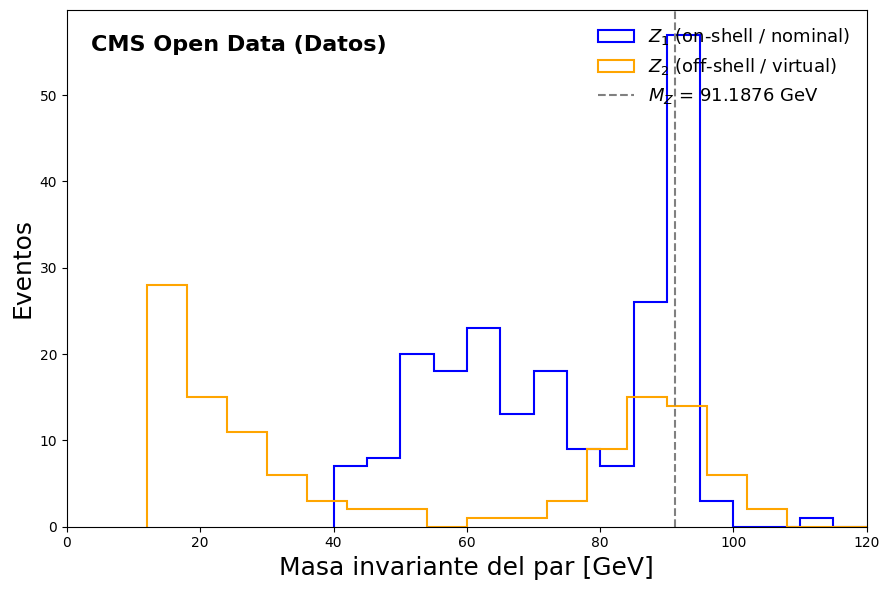

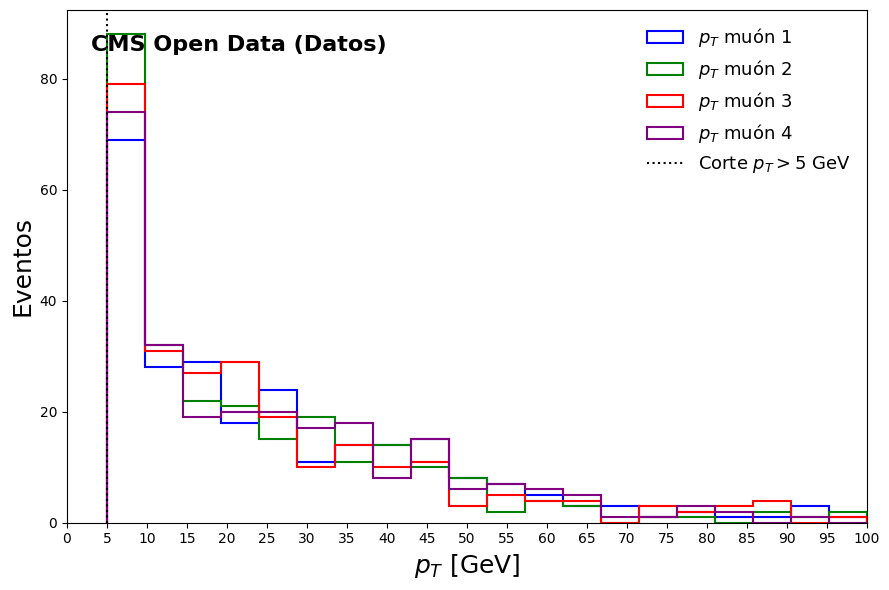

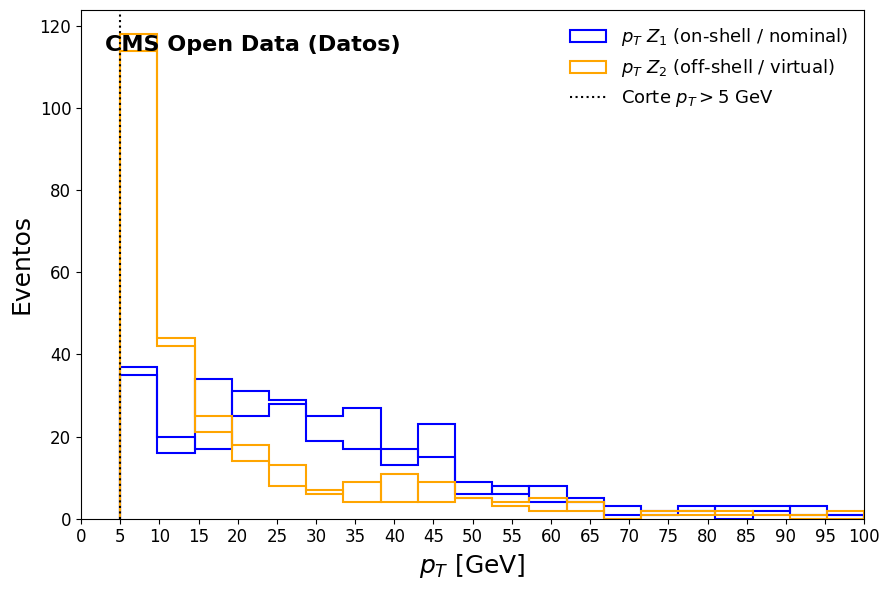

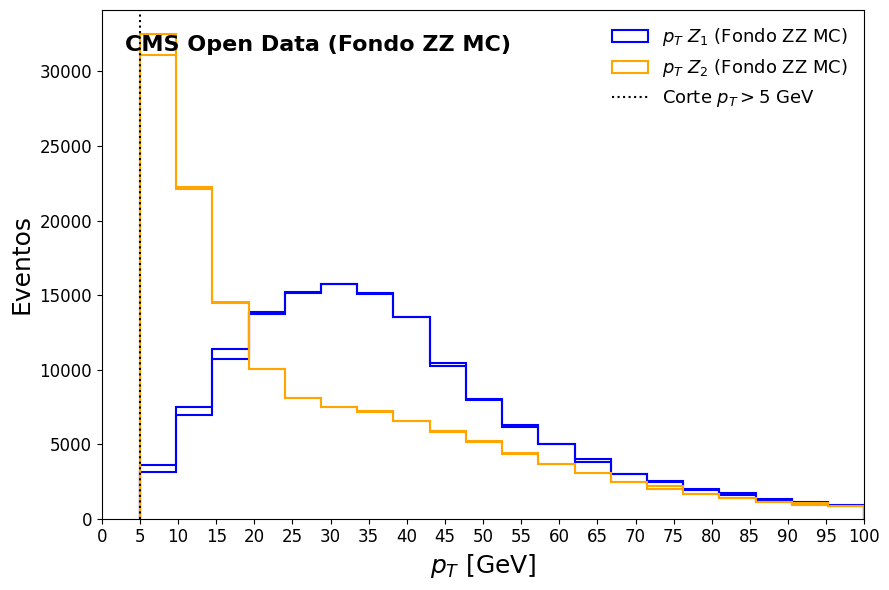

In [11]:
#  Gráfica: Masa invariante de los pares Z1 y Z2 (Datos Reales)
fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    df_final["mZ1"],
    bins=16,
    range=(40, 120),
    histtype="step",
    color="blue",
    linewidth=1.5,
    label="$Z_1$ (on-shell / nominal)",
)
ax.hist(
    df_final["mZ2"],
    bins=18,
    range=(12, 120),
    histtype="step",
    color="orange",
    linewidth=1.5,
    label="$Z_2$ (off-shell / virtual)",
)
ax.axvline(
    Z_Mass_Nominal,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label=f"$M_Z$ = {Z_Mass_Nominal} GeV",
)

ax.set_xlabel("Masa invariante del par [GeV]", fontsize=18)
ax.set_ylabel("Eventos", fontsize=18)
ax.set_xlim(0, 120)

ax.text(
    0.03,
    0.92,
    "CMS Open Data (Datos)",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
)
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()

# Gráfica: pT de los 4 muones individuales (Datos Reales)
fig, ax = plt.subplots(figsize=(9, 6))
colores = ["blue", "green", "red", "purple"]
for i, color in zip(range(1, 5), colores):
    ax.hist(
        df_final[f"pt{i}"],
        bins=20,
        range=(5, 100),
        histtype="step",
        color=color,
        linewidth=1.5,
        label=f"$p_T$ muón {i}",
    )

ax.axvline(5, color="black", linestyle=":", linewidth=1.5, label="Corte $p_T > 5$ GeV")
ax.set_xlabel("$p_T$ [GeV]", fontsize=18)
ax.set_ylabel("Eventos", fontsize=18) 
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 5))
ax.text(
    0.03,
    0.92,
    "CMS Open Data (Datos)",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
)
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()


# Extraer el pT de los muones que forman Z1 y Z2 (Datos)
todos_indices = {1, 2, 3, 4}

pt_Z1_a = np.zeros(len(df_final))
pt_Z1_b = np.zeros(len(df_final))
for i in range(1, 5):
    mask_a = (df_final["Z1_idx_a"] == i)
    pt_Z1_a[mask_a] = df_final.loc[mask_a, f"pt{i}"]
    mask_b = (df_final["Z1_idx_b"] == i)
    pt_Z1_b[mask_b] = df_final.loc[mask_b, f"pt{i}"] 

df_final["pt_Z1a"] = pt_Z1_a
df_final["pt_Z1b"] = pt_Z1_b

pt_Z2_a = np.zeros(len(df_final))
pt_Z2_b = np.zeros(len(df_final))
idx_a_arr = df_final["Z1_idx_a"].astype(int).to_numpy()
idx_b_arr = df_final["Z1_idx_b"].astype(int).to_numpy()
pt_matrix = df_final[["pt1", "pt2", "pt3", "pt4"]].to_numpy()

for idx in range(len(df_final)):
    usados = {idx_a_arr[idx], idx_b_arr[idx]}
    restantes = sorted(todos_indices - usados)
    pt_Z2_a[idx] = pt_matrix[idx, restantes[0]-1]
    pt_Z2_b[idx] = pt_matrix[idx, restantes[1]-1]

df_final["pt_Z2a"] = pt_Z2_a
df_final["pt_Z2b"] = pt_Z2_b


# Gráfica: pT de los muones de Z1 y Z2 (Datos)
fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    df_final["pt_Z1a"], bins=20, range=(5, 100),
    histtype="step", color="blue", linewidth=1.5,
    label="$p_T$ $Z_1$ (on-shell / nominal)",
)
ax.hist(
    df_final["pt_Z1b"], bins=20, range=(5, 100),
    histtype="step", color="blue", linewidth=1.5,
)
ax.hist(
    df_final["pt_Z2a"], bins=20, range=(5, 100),
    histtype="step", color="orange", linewidth=1.5,
    label="$p_T$ $Z_2$ (off-shell / virtual)",
)
ax.hist(
    df_final["pt_Z2b"], bins=20, range=(5, 100),
    histtype="step", color="orange", linewidth=1.5,
)

ax.axvline(5, color="black", linestyle=":", linewidth=1.5, label="Corte $p_T > 5$ GeV")

ax.set_xlabel("$p_T$ [GeV]", fontsize=18)
ax.set_ylabel("Eventos", fontsize=18)
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 5))

ax.tick_params(axis='both', labelsize=12)
ax.text(
    0.03,
    0.92,
    "CMS Open Data (Datos)",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
)
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()


# Extraer el pT de los muones para el Fondo ZZ MC (df_final_zz)
pt_Z1_a_zz = np.zeros(len(df_final_zz))
pt_Z1_b_zz = np.zeros(len(df_final_zz))
for i in range(1, 5):
    mask_a = (df_final_zz["Z1_idx_a"] == i)
    pt_Z1_a_zz[mask_a] = df_final_zz.loc[mask_a, f"pt{i}"]
    mask_b = (df_final_zz["Z1_idx_b"] == i)
    pt_Z1_b_zz[mask_b] = df_final_zz.loc[mask_b, f"pt{i}"] 

df_final_zz["pt_Z1a"] = pt_Z1_a_zz
df_final_zz["pt_Z1b"] = pt_Z1_b_zz

pt_Z2_a_zz = np.zeros(len(df_final_zz))
pt_Z2_b_zz = np.zeros(len(df_final_zz))
idx_a_arr_zz = df_final_zz["Z1_idx_a"].astype(int).to_numpy()
idx_b_arr_zz = df_final_zz["Z1_idx_b"].astype(int).to_numpy()
pt_matrix_zz = df_final_zz[["pt1", "pt2", "pt3", "pt4"]].to_numpy()

for idx in range(len(df_final_zz)):
    usados = {idx_a_arr_zz[idx], idx_b_arr_zz[idx]}
    restantes = sorted(todos_indices - usados)
    pt_Z2_a_zz[idx] = pt_matrix_zz[idx, restantes[0]-1]
    pt_Z2_b_zz[idx] = pt_matrix_zz[idx, restantes[1]-1]

df_final_zz["pt_Z2a"] = pt_Z2_a_zz
df_final_zz["pt_Z2b"] = pt_Z2_b_zz


# Gráfica: pT de los muones de Z1 y Z2 para el Fondo ZZ MC
fig, ax = plt.subplots(figsize=(9, 6))

ax.hist(
    df_final_zz["pt_Z1a"], bins=20, range=(5, 100),
    histtype="step", color="blue", linewidth=1.5,
    label="$p_T$ $Z_1$ (Fondo ZZ MC)",
)
ax.hist(
    df_final_zz["pt_Z1b"], bins=20, range=(5, 100),
    histtype="step", color="blue", linewidth=1.5,
)
ax.hist(
    df_final_zz["pt_Z2a"], bins=20, range=(5, 100),
    histtype="step", color="orange", linewidth=1.5,
    label="$p_T$ $Z_2$ (Fondo ZZ MC)",
)
ax.hist(
    df_final_zz["pt_Z2b"], bins=20, range=(5, 100),
    histtype="step", color="orange", linewidth=1.5,
)

ax.axvline(5, color="black", linestyle=":", linewidth=1.5, label="Corte $p_T > 5$ GeV")

ax.set_xlabel("$p_T$ [GeV]", fontsize=18)
ax.set_ylabel("Eventos", fontsize=18)
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 5))

ax.tick_params(axis='both', labelsize=12)
ax.text(
    0.03,
    0.92,
    "CMS Open Data (Fondo ZZ MC)",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
)
ax.legend(loc="upper right", frameon=False, fontsize=13)
plt.tight_layout()
plt.show()

Datos reales filtrados: 98
Higgs filtrado:         10999
Fondo ZZ MC filtrado:   100338
Peso Higgs: 0.000248
Peso ZZ:    8.158652e-04


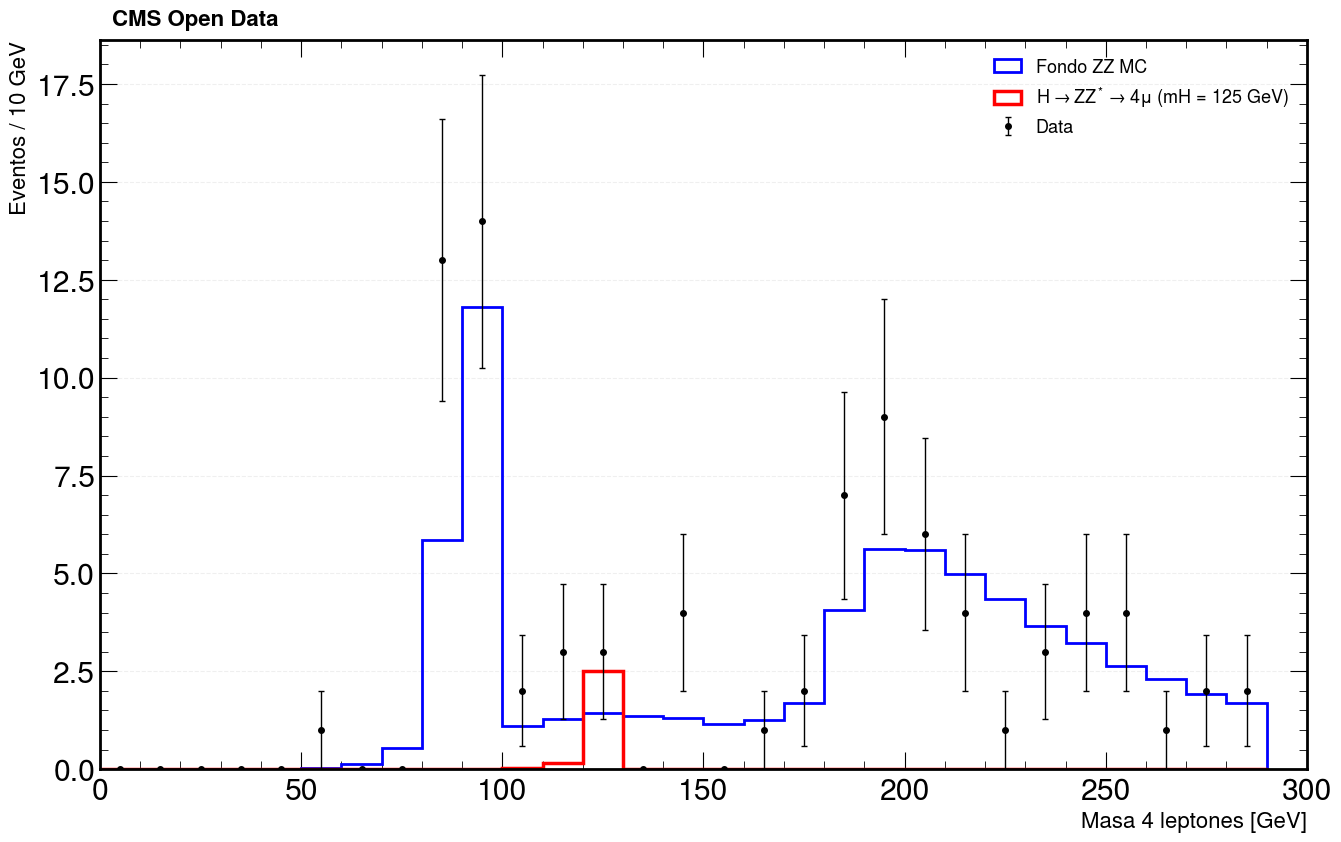

In [24]:
# Estilo CMS 
hep.style.use("CMS")

# Parámetros Físicos
m_mu = 0.10566  # Masa del muón [GeV/c²]

# Reconstrucción del 4-vector del sistema de 4 muones
def calcular_masa(df):
    px = 0; py = 0; pz = 0; E = 0
    for i in range(1, 5):
        pxi = df[f"pt{i}"] * np.cos(df[f"phi{i}"])
        pyi = df[f"pt{i}"] * np.sin(df[f"phi{i}"])
        pzi = df[f"pt{i}"] * np.sinh(df[f"eta{i}"])
        Ei  = np.sqrt(pxi**2 + pyi**2 + pzi**2 + m_mu**2)
        px += pxi; py += pyi; pz += pzi; E += Ei
        
    argumento_raiz = np.maximum(0, E**2 - (px**2 + py**2 + pz**2))
    return np.sqrt(argumento_raiz)


# Filtros y Masa para Datos Reales (df_final_mu) 

for i in range(1, 5):
    ip3d_d = np.sqrt(df_final_mu[f"dxy{i}"] ** 2 + df_final_mu[f"dz{i}"] ** 2)
    sig_d = np.sqrt(df_final_mu[f"dxyErr{i}"] ** 2 + df_final_mu[f"dzErr{i}"] ** 2)
    df_final_mu[f"sip3d{i}"] = ip3d_d / sig_d

mask_pt_d  = (df_final_mu["pt1"]>5)  & (df_final_mu["pt2"]>5)  & (df_final_mu["pt3"]>5)  & (df_final_mu["pt4"]>5)
mask_eta_d = (df_final_mu["eta1"].abs()<2.4) & (df_final_mu["eta2"].abs()<2.4) & (df_final_mu["eta3"].abs()<2.4) & (df_final_mu["eta4"].abs()<2.4)
mask_iso_d = (df_final_mu["iso1"]<0.40) & (df_final_mu["iso2"]<0.40) & (df_final_mu["iso3"]<0.40) & (df_final_mu["iso4"]<0.40)
mask_sip_d = (df_final_mu["sip3d1"]<4) & (df_final_mu["sip3d2"]<4) & (df_final_mu["sip3d3"]<4) & (df_final_mu["sip3d4"]<4)
mask_dxy_data = (df_final_mu["dxy1"].abs() < 0.5) & (df_final_mu["dxy2"].abs() < 0.5) & (df_final_mu["dxy3"].abs() < 0.5) & (df_final_mu["dxy4"].abs() < 0.5)
mask_dz_data  = (df_final_mu["dz1"].abs() < 1.0)  & (df_final_mu["dz2"].abs() < 1.0)  & (df_final_mu["dz3"].abs() < 1.0)  & (df_final_mu["dz4"].abs() < 1.0)

df_data_f = df_final_mu[mask_pt_d & mask_eta_d & mask_iso_d & mask_sip_d & mask_dxy_data & mask_dz_data].copy()
df_data_f = identificar_Z_onoff(df_data_f)
df_data_f = df_data_f[(df_data_f["mZ1"] > 40) & (df_data_f["mZ1"] < 120) &(df_data_f["mZ2"] > 12) & (df_data_f["mZ2"] < 120)].copy()
df_data_f["M"] = calcular_masa(df_data_f)

# Filtros y Masa para Higgs MC (df_final_higgs_mu) 

for i in range(1, 5):
  ip3d_h = np.sqrt(df_final_higgs_mu[f"dxy{i}"] ** 2 + df_final_higgs_mu[f"dz{i}"] ** 2)
  sig_h = np.sqrt(df_final_higgs_mu[f"dxyErr{i}"] ** 2 + df_final_higgs_mu[f"dzErr{i}"] ** 2)
  df_final_higgs_mu[f"sip3d{i}"] = ip3d_h / sig_h

mask_pt_h = ((df_final_higgs_mu["pt1"] > 5)  & (df_final_higgs_mu["pt2"] > 5)  & (df_final_higgs_mu["pt3"] > 5)  & (df_final_higgs_mu["pt4"] > 5)& (df_final_higgs_mu["pt4"] > 5))
mask_eta_h = ((df_final_higgs_mu["eta1"].abs() < 2.4)& (df_final_higgs_mu["eta2"].abs() < 2.4)& (df_final_higgs_mu["eta3"].abs() < 2.4)& (df_final_higgs_mu["eta4"].abs() < 2.4))
mask_iso_h = ((df_final_higgs_mu["iso1"] < 0.40)& (df_final_higgs_mu["iso2"] < 0.40)& (df_final_higgs_mu["iso3"] < 0.40)& (df_final_higgs_mu["iso4"] < 0.40))
mask_sip_h = ((df_final_higgs_mu["sip3d1"] < 4)& (df_final_higgs_mu["sip3d2"] < 4)& (df_final_higgs_mu["sip3d3"] < 4)& (df_final_higgs_mu["sip3d4"] < 4))
mask_dxy_h = ((df_final_higgs_mu["dxy1"].abs() < 0.5)& (df_final_higgs_mu["dxy2"].abs() < 0.5)& (df_final_higgs_mu["dxy3"].abs() < 0.5)& (df_final_higgs_mu["dxy4"].abs() < 0.5))
mask_dz_h = ((df_final_higgs_mu["dz1"].abs() < 1.0)& (df_final_higgs_mu["dz2"].abs() < 1.0)& (df_final_higgs_mu["dz3"].abs() < 1.0) & (df_final_higgs_mu["dz4"].abs() < 1.0))

df_higgs_f = df_final_higgs_mu[mask_pt_h & mask_eta_h & mask_iso_h & mask_sip_h & mask_dxy_h & mask_dz_h].copy()
df_higgs_f = identificar_Z_onoff(df_higgs_f)
df_higgs_f = df_higgs_f[(df_higgs_f["mZ1"] > 40)& (df_higgs_f["mZ1"] < 120)& (df_higgs_f["mZ2"] > 12)& (df_higgs_f["mZ2"] < 120)].copy()
df_higgs_f["M"] = calcular_masa(df_higgs_f)

# Filtros y Masa para Fondo ZZ MC (df_final_zz_mu) 

for i in range(1, 5):
    ip3d_zz = np.sqrt(df_final_zz_mu[f"dxy{i}"] ** 2 + df_final_zz_mu[f"dz{i}"] ** 2)
    sig_zz = np.sqrt(df_final_zz_mu[f"dxyErr{i}"] ** 2 + df_final_zz_mu[f"dzErr{i}"] ** 2)
    df_final_zz_mu[f"sip3d{i}"] = ip3d_zz / sig_zz

mask_pt_zz  = (df_final_zz_mu["pt1"]>5)  & (df_final_zz_mu["pt2"]>5)  & (df_final_zz_mu["pt3"]>5)  & (df_final_zz_mu["pt4"]>5)
mask_eta_zz = (df_final_zz_mu["eta1"].abs()<2.4) & (df_final_zz_mu["eta2"].abs()<2.4) & (df_final_zz_mu["eta3"].abs()<2.4) & (df_final_zz_mu["eta4"].abs()<2.4)
mask_iso_zz = (df_final_zz_mu["iso1"]<0.40) & (df_final_zz_mu["iso2"]<0.40) & (df_final_zz_mu["iso3"]<0.40) & (df_final_zz_mu["iso4"]<0.40)
mask_sip_zz = (df_final_zz_mu["sip3d1"]<4) & (df_final_zz_mu["sip3d2"]<4) & (df_final_zz_mu["sip3d3"]<4) & (df_final_zz_mu["sip3d4"]<4)
mask_dxy_zz = (df_final_zz_mu["dxy1"].abs() < 0.5) & (df_final_zz_mu["dxy2"].abs() < 0.5) & (df_final_zz_mu["dxy3"].abs() < 0.5) & (df_final_zz_mu["dxy4"].abs() < 0.5)
mask_dz_zz  = (df_final_zz_mu["dz1"].abs() < 1.0)  & (df_final_zz_mu["dz2"].abs() < 1.0)  & (df_final_zz_mu["dz3"].abs() < 1.0)  & (df_final_zz_mu["dz4"].abs() < 1.0)

df_zz_f = df_final_zz_mu[mask_pt_zz & mask_eta_zz & mask_iso_zz & mask_sip_zz & mask_dxy_zz & mask_dz_zz].copy()
df_zz_f = identificar_Z_onoff(df_zz_f)
df_zz_f = df_zz_f[(df_zz_f["mZ1"] > 40) & (df_zz_f["mZ1"] < 120) &(df_zz_f["mZ2"] > 12) & (df_zz_f["mZ2"] < 120)].copy()
df_zz_f["M"] = calcular_masa(df_zz_f)


print("Datos reales filtrados:", len(df_data_f))
print("Higgs filtrado:        ", len(df_higgs_f))
print("Fondo ZZ MC filtrado:  ", len(df_zz_f))

# Pesos oficiales del CERN
lumi    = 11.46 * 1000
w_higgs = (0.0065 * lumi) / 299973.0
w_zz    = (0.077 * 1.386 * lumi) / 1499064.0

print(f"Peso Higgs: {w_higgs:.6f}")
print(f"Peso ZZ:    {w_zz:.6e}")


# Gráfico unificado con Datos, Higgs y Fondo ZZ MC (Escala Lineal)
mis_bins = np.arange(0, 300, 10)

plt.figure(figsize=(14, 9))

# Fondo ZZ MC
plt.hist(df_zz_f["M"], bins=mis_bins,
         weights=np.full(len(df_zz_f), w_zz),
         label="Fondo ZZ MC", color="blue", histtype='step', linewidth=2)

# Señal de Higgs
plt.hist(df_higgs_f["M"], bins=mis_bins,
         weights=np.full(len(df_higgs_f), w_higgs),
         label=r"$H \to ZZ^* \to 4\mu$ (mH = 125 GeV)", color="red", histtype='step', linewidth=2.5)

# Datos Reales
counts, bin_edges = np.histogram(df_data_f["M"], bins=mis_bins)
bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2
plt.errorbar(bin_centers, counts, yerr=np.sqrt(counts),
             fmt='o', color='black', markersize=4,
             capsize=2, elinewidth=1, linestyle='none', label='Data')

# Estética de la gráfica
ax = plt.gca()
ax.text(0.01, 1.02, "CMS Open Data", transform=ax.transAxes,
        fontsize=16, fontweight='bold', fontstyle='normal', ha='left')
plt.xlabel("Masa 4 leptones [GeV]", fontsize=16)
plt.ylabel("Eventos / 10 GeV", fontsize=16)
plt.xlim(0, 300)

plt.legend(loc='upper right', frameon=False, fontsize=13)
plt.grid(axis='y', alpha=0.2, linestyle='--')
plt.tight_layout()
plt.show()

In [25]:
# Guardar los DataFrames 
df_data_f.to_parquet("df_data_mu.parquet")
df_higgs_f.to_parquet("df_higgs_mu.parquet")
df_zz_f.to_parquet("df_zz_mu.parquet")

   Conteo Total Combinado  
Datos reales totales: 204
Higgs MC total:       29013
Fondo ZZ MC total:    215507
Peso Higgs: 0.000251
Peso ZZ:    8.244083e-04


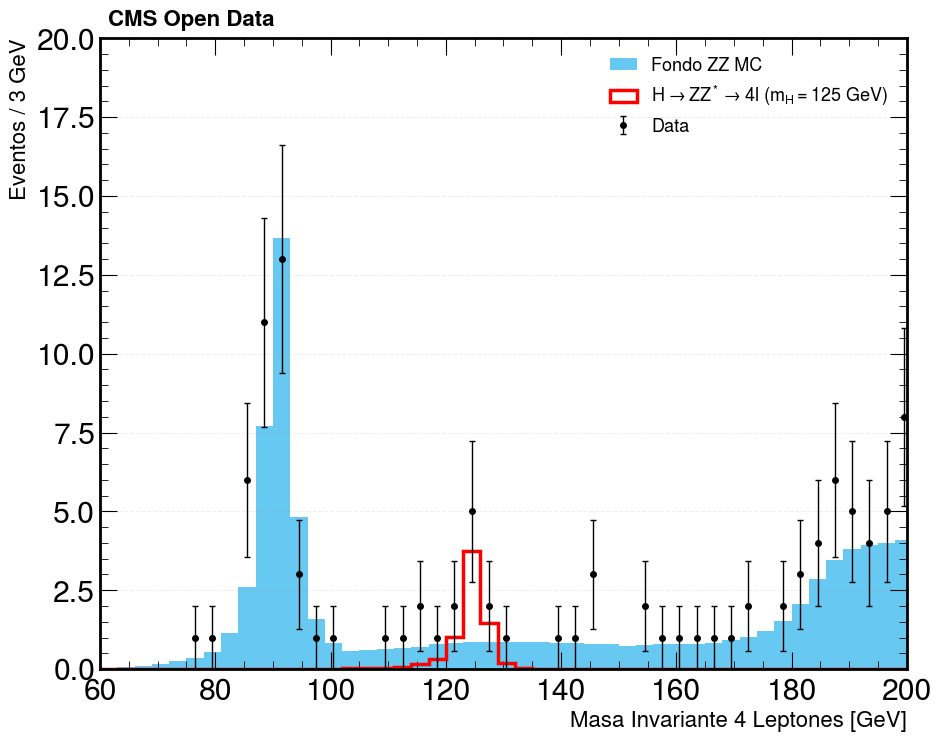

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mplhep as hep

# Estilo CMS
hep.style.use("CMS")

# 1. Cargar los DataFrames de los tres canales desde los archivos Parquet
# Canal Muones (4mu)
df_data_4mu = pd.read_parquet("df_data_mu.parquet")
df_higgs_4mu = pd.read_parquet("df_higgs_mu.parquet")
df_zz_4mu = pd.read_parquet("df_zz_mu.parquet")

# Canal Mixto (2el2mu)
df_data_mix = pd.read_parquet("df_data_2el2mu.parquet")
df_higgs_mix = pd.read_parquet("df_higgs_2el2mu.parquet")
df_zz_mix = pd.read_parquet("df_zz_2el2mu.parquet")

# Canal Electrones (4el)
df_data_4el = pd.read_parquet("df_data_4el.parquet")
df_higgs_4el = pd.read_parquet("df_higgs_4el.parquet")
df_zz_4el = pd.read_parquet("df_zz_4el.parquet")

# 2. Concatenar los canales para formar un solo conjunto global por cada tipo
df_data_all = pd.concat([df_data_4mu, df_data_4el, df_data_mix], ignore_index=True)
df_higgs_all = pd.concat([df_higgs_4mu, df_higgs_4el, df_higgs_mix], ignore_index=True)
df_zz_all = pd.concat([df_zz_4mu, df_zz_4el, df_zz_mix], ignore_index=True)

print("   Conteo Total Combinado  ")
print(f"Datos reales totales: {len(df_data_all)}")
print(f"Higgs MC total:       {len(df_higgs_all)}")
print(f"Fondo ZZ MC total:    {len(df_zz_all)}")

# 3. Pesos oficiales del CERN
lumi = 11.58 * 1000
w_higgs = (0.0065 * lumi) / 299973.0
w_zz = (0.077 * 1.386 * lumi) / 1499064.0

print(f"Peso Higgs: {w_higgs:.6f}")
print(f"Peso ZZ:    {w_zz:.6e}")

# 4. Gráfica con tu estilo personalizado (Bins de 3 GeV)
mis_bins = np.arange(0, 300, 3)

plt.figure(figsize=(10, 8))

# Fondo ZZ MC (Combinado) con estilo de área rellenada
plt.hist(
    df_zz_all["M"],
    bins=mis_bins,
    weights=np.full(len(df_zz_all), w_zz),
    label="Fondo ZZ MC",
    color="#67C8F2",
    histtype="stepfilled",
    alpha=1.0,
)

# Señal de Higgs (Combinado)
plt.hist(
    df_higgs_all["M"],
    bins=mis_bins,
    weights=np.full(len(df_higgs_all), w_higgs),
    label=r"$H \to ZZ^* \to 4l$ ($m_H = 125$ GeV)",
    color="red",
    histtype="step",
    linewidth=2.5,
)

# Datos Reales (Combinado, filtrando ceros para evitar cruces en y=0 si los hubiera)
counts, bin_edges = np.histogram(df_data_all["M"], bins=mis_bins)
bin_centers = (bin_edges[1:] + bin_edges[:-1]) / 2
mask_validos = counts > 0

plt.errorbar(
    bin_centers[mask_validos],
    counts[mask_validos],
    yerr=np.sqrt(counts[mask_validos]),
    fmt="o",
    color="black",
    markersize=4,
    capsize=2,
    elinewidth=1,
    linestyle="none",
    label="Data",
)

# Estética y textos de tu preferencia
ax = plt.gca()
ax.text(
    0.01,
    1.02,
    "CMS Open Data",
    transform=ax.transAxes,
    fontsize=16,
    fontweight="bold",
    fontstyle="normal",
    ha="left",
)
plt.xlabel("Masa Invariante 4 Leptones [GeV]", fontsize=16)
plt.ylabel("Eventos / 3 GeV", fontsize=16)
plt.xlim(60, 200)
plt.ylim(0, 20)

plt.legend(loc="upper right", frameon=False, fontsize=13)
plt.grid(axis="y", alpha=0.2, linestyle="--")
plt.tight_layout()

# Opcional: guardar tu gráfica final combinada
plt.savefig("espectro_masa_4l_estilo_personalizado.png", dpi=300)
plt.show()